#[3] Architecture Pattern

In [1]:
!pip install -qU langgraph langchain langchain-openai

In [105]:
from dotenv import load_dotenv
import os
load_dotenv(dotenv_path = ".env", override=True)

print(".env 내 OPENAI_API_KEY가 환경변수에 할당됐습니다:", os.environ["OPENAI_API_KEY"][:5]+"*****")

.env 내 OPENAI_API_KEY가 환경변수에 할당됐습니다: sk-pr*****


[Workflow 공식문서](https://docs.langchain.com/oss/python/langgraph/workflows-agents#orchestrator-worker)

#1 . Prompt Chaining

##1-1. Model 정의

In [100]:
from langchain.chat_models import init_chat_model

model = init_chat_model("gpt-4.1-mini", temperature=0.5)

##1-2. State 정의

In [101]:
from typing import TypedDict

class JokeState(TypedDict):
    topic: str          # 초기 주제
    draft_joke: str     # 1단계: 초안
    improved_joke: str  # 2단계: 수정안
    final_joke: str     # 3단계: 최종 결과

##1-3. Node 정의

In [ ]:
# [Step 1] 초안 생성 노드
# oo주제로 개그 만들기
def generate_joke(state: JokeState):
    topic = state["topic"]
    print(f"\n--- [1단계] '{topic}' 주제로 농담 초안 생성 중 ---")

    msg = model.invoke(f"'{topic}'에 대한 짧고 재미있는 농담을 하나 만들어줘. 다른 말은 하지 말고 농담 하나만 해")
    print(f"   ㄴ 초안: {msg.content}\n")
    return {"draft_joke": msg.content}

In [31]:
# [Step 2] 수정 노드
# 아재개그 스타일로 개선하기
def improve_joke(state: JokeState):
    original_joke = state["draft_joke"]
    print(f"\n--- [2단계] 더 웃기게 수정 중 (아재개그 스타일) ---")

    prompt = f"""
    다음 농담을 보고, 더 썰렁하고 재미있는 '아재개그' 스타일로 개선해줘. 다른 말은 하지 말고 하나만 답변해.
    원문: {original_joke}
    """
    msg = model.invoke(prompt)
    print(f"   ㄴ 개선: {msg.content}\n")
    return {"improved_joke": msg.content}

In [32]:
# [Step 3] 최종 포장 노드
# 이모지 넣어 완성하기
def polish_joke(state: JokeState):
    improved_joke = state["improved_joke"]
    print(f"\n--- [3단계] 이모지 추가 및 마무리 ---")

    prompt = f"""
    다음 농담에 적절한 이모지를 듬뿍 넣어서 SNS에 올리기 좋게 꾸며줘.
    농담: {improved_joke}
    """
    msg = model.invoke(prompt)
    print(f"   ㄴ 최종: {msg.content}\n")
    return {"final_joke": msg.content}

##1-4. 그래프 생성

In [33]:
from langgraph.graph import StateGraph, START, END

# 그래프 객체 생성
Gen_joke = StateGraph(JokeState)
# 노드 등록
Gen_joke.add_node("generate_joke", generate_joke)
Gen_joke.add_node("improve_joke", improve_joke)
Gen_joke.add_node("polish_joke", polish_joke)

# 엣지 연결: 일직선으로 연결 (Linear Chain)

# START -> 1단계 -> 2단계 -> 3단계 -> END
Gen_joke.add_edge(START, "generate_joke")
Gen_joke.add_edge("generate_joke", "improve_joke")
Gen_joke.add_edge("improve_joke", "polish_joke")
Gen_joke.add_edge("polish_joke", END)


# 컴파일

chain = Gen_joke.compile()


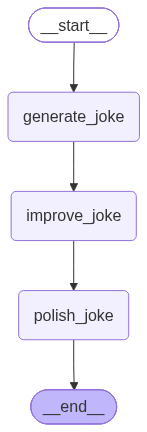

In [34]:
chain

##1-5. 실행

In [ ]:
inputs = {"topic": ""}
result = chain.invoke(inputs)


--- [1단계] '고양이' 주제로 농담 초안 생성 중 ---
   ㄴ 초안: 고양이가 컴퓨터를 싫어하는 이유? 마우스가 너무 많아서!


--- [2단계] 더 웃기게 수정 중 (아재개그 스타일) ---
   ㄴ 개선: 고양이가 컴퓨터 싫어하는 이유? 마우스가 너무 많아서 클릭질 못 하거든!


--- [3단계] 이모지 추가 및 마무리 ---
   ㄴ 최종: 고양이가 컴퓨터 싫어하는 이유? 🐱💻  
마우스가 너무 많아서 🐭🐭🐭  
클릭질 못 하거든! 😂🖱️🚫  

#고양이 #컴퓨터 #마우스 #웃긴농담 #냥스타그램 #펫스타그램 🐾💖



In [ ]:
print(f"주제: {result['topic']}")
print(f"1차 초안: {result['draft_joke']}")
print(f"2차 수정: {result['improved_joke']}")
print("-" * 30)
print(f"최종 완성:\n{result['final_joke']}")

In [103]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

class PoemState(TypedDict):
    word: str            # 삼행시 제시어 (예: "고양이")
    draft_poem: str      # 1단계: 초안
    improved_poem: str   # 2단계: 수정안
    final_poem: str      # 3단계: 최종 결과


# [Step 1] 초안 생성 노드
# 제시어 글자마다 한 줄씩 삼행시 짓기
def generate_poem(state: PoemState):
    word = state["word"]
    print(f"\n--- [1단계] '{word}' 삼행시 초안 생성 중 ---")

    prompt = f"""
    '{word}'로 {len(word)}행시를 지어줘.
    각 줄은 '{"', '".join(word)}' 글자로 순서대로 시작하고, 형식은 '글자: 문장'으로 해.
    다른 말은 하지 말고 {len(word)}행시만 답변해.
    """
    msg = model.invoke(prompt)
    print(f"   ㄴ 초안:\n{msg.content}\n")
    return {"draft_poem": msg.content}


# [Step 2] 수정 노드
# 마지막 줄 반전이 있는 웃긴 삼행시로 개선하기
def improve_poem(state: PoemState):
    word = state["word"]
    draft_poem = state["draft_poem"]
    print(f"\n--- [2단계] 반전 있게 수정 중 ---")

    prompt = f"""
    다음 '{word}' 삼행시를 마지막 줄에서 빵 터지는 반전이 있도록 재미있게 고쳐줘
    각 줄의 첫 글자('{"', '".join(word)}')와 형식은 반드시 유지해. 다른 말은 하지 말고 삼행시만 답변해.
    원문:
    {draft_poem}
    """
    msg = model.invoke(prompt)
    print(f"   ㄴ 개선:\n{msg.content}\n")
    return {"improved_poem": msg.content}


# [Step 3] 최종 포장 노드
# 이모지 넣어 완성하기
def polish_poem(state: PoemState):
    improved_poem = state["improved_poem"]
    print(f"\n--- [3단계] 이모지 추가 및 마무리 ---")

    prompt = f"""
    다음 삼행시에 어울리는 이모지를 넣어서 SNS에 올리기 좋게 꾸며줘.
    각 줄의 첫 글자는 바꾸지 마.
    삼행시:
    {improved_poem}
    """
    msg = model.invoke(prompt)
    print(f"   ㄴ 최종:\n{msg.content}\n")
    return {"final_poem": msg.content}


# 그래프 생성: START -> 1단계 -> 2단계 -> 3단계 -> END
Gen_poem = StateGraph(PoemState)
Gen_poem.add_node("generate_poem", generate_poem)
Gen_poem.add_node("improve_poem", improve_poem)
Gen_poem.add_node("polish_poem", polish_poem)

Gen_poem.add_edge(START, "generate_poem")
Gen_poem.add_edge("generate_poem", "improve_poem")
Gen_poem.add_edge("improve_poem", "polish_poem")
Gen_poem.add_edge("polish_poem", END)

poem_chain = Gen_poem.compile()

# 실행
result = poem_chain.invoke({"word": "고양이"})
print(f"최종 완성:\n{result['final_poem']}")



--- [1단계] '고양이' 삼행시 초안 생성 중 ---
   ㄴ 초안:
고: 고운 털 사이로 햇살이 스며들고  
양: 양탄자 위에서 조용히 꿈을 꾸네  
이: 이 순간이 영원하길 바라며 잠든다


--- [2단계] 반전 있게 수정 중 ---
   ㄴ 개선:
고: 고양이는 오늘도 우아하게 걷고  
양: 양말 한 짝을 또 어디다 뒀지?  
이: 이게 다 내 발 밑에 있었네!


--- [3단계] 이모지 추가 및 마무리 ---
   ㄴ 최종:
고: 고양이는 오늘도 우아하게 걷고 🐈‍⬛✨  
양: 양말 한 짝을 또 어디다 뒀지? 🧦🤔  
이: 이게 다 내 발 밑에 있었네! 👣😂  

#고양이 #우아함 #양말찾기 #일상 #귀여움

최종 완성:
고: 고양이는 오늘도 우아하게 걷고 🐈‍⬛✨  
양: 양말 한 짝을 또 어디다 뒀지? 🧦🤔  
이: 이게 다 내 발 밑에 있었네! 👣😂  

#고양이 #우아함 #양말찾기 #일상 #귀여움


#2 . Parallelization (병렬 처리)

##2-1. Model 정의

In [47]:
model = init_chat_model("gpt-4.1-mini")

##2-2. State 정의

In [48]:
from typing import TypedDict

class WriterState(TypedDict):
    topic: str          # 주제
    poem: str           # 시 (결과물 A)
    story: str          # 소설 (결과물 B)
    joke: str           # 농담 (결과물 C)
    final_report: str   # 최종 편집본

##2-3. Node 정의

In [49]:
# [Worker A] 시인 노드
def write_poem(state: WriterState):
    topic = state["topic"]
    print(f"   [Worker A] '{topic}' 주제로 시(Poem) 작성 시작...")

    msg = model.invoke(f"'{topic}'에 대한 아름다운 시를 짧게 써줘.")
    return {"poem": msg.content}

In [50]:
# [Worker B] 소설가 노드
def write_story(state: WriterState):
    topic = state["topic"]
    print(f"   [Worker B] '{topic}' 주제로 소설(Story) 작성 시작...")

    msg = model.invoke(f"'{topic}'에 대한 감동적인 짧은 이야기를 써줘.")
    return {"story": msg.content}

In [51]:
# [Worker C] 개그맨 노드
def write_joke(state: WriterState):
    topic = state["topic"]
    print(f"   [Worker C] '{topic}' 주제로 농담(Joke) 작성 시작...")

    msg = model.invoke(f"'{topic}'에 대한 재미있는 아재개그를 하나 해줘.")
    return {"joke": msg.content}

In [52]:
# [Aggregator] 편집장 노드 (모든 결과를 취합)
def aggregator(state: WriterState):
    print("\n--- [Aggregator] 모든 원고 도착! 최종 편집 중 ---")

    # State에 저장된 각 결과물을 꺼내서 합침
    final_text = f"""
    [주제: {state['topic']} 종합 선물세트]

    1. 시 (Poem)
    ----------------
    {state['poem']}

    2. 소설 (Story)
    ----------------
    {state['story']}

    3. 농담 (Joke)
    ----------------
    {state['joke']}
    """
    return {"final_report": final_text}

##2-4. 그래프 생성

In [53]:
workflow = StateGraph(WriterState)

# 노드 추가
workflow.add_node("write_poem", write_poem)
workflow.add_node("write_story", write_story)
workflow.add_node("write_joke", write_joke)
workflow.add_node("aggregator", aggregator)

# 엣지 연결: START에서 3개의 노드로 동시에 뻗어 나가기 (Fan-out)
workflow.add_edge(START, "write_poem")
workflow.add_edge(START, "write_story")
workflow.add_edge(START, "write_joke")

# 3개의 노드가 모두 하나의 노드로 모이기 (Fan-in)
workflow.add_edge("write_poem", "aggregator")
workflow.add_edge("write_story", "aggregator")
workflow.add_edge("write_joke", "aggregator")

workflow.add_edge("aggregator", END)

# 컴파일
app = workflow.compile()


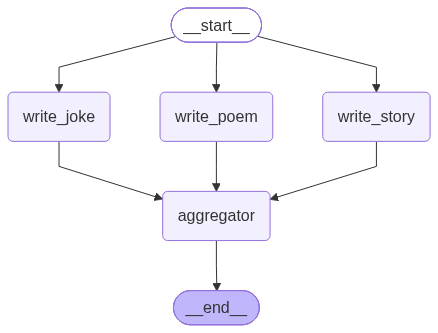

In [54]:
app

##2-5. 실행

In [55]:
inputs = {"topic": "직장인의 월요일"}
result = app.invoke(inputs)

   [Worker C] '직장인의 월요일' 주제로 농담(Joke) 작성 시작...   [Worker A] '직장인의 월요일' 주제로 시(Poem) 작성 시작...

   [Worker B] '직장인의 월요일' 주제로 소설(Story) 작성 시작...

--- [Aggregator] 모든 원고 도착! 최종 편집 중 ---


In [56]:
result

{'topic': '직장인의 월요일',
 'poem': '월요일 아침, 창가에 스며든 빛  \n잠든 꿈을 깨우는 첫 걸음  \n서둘러 맞이하는 하루 속에  \n희망 한 조각, 미소 한 자락 걸친다.',
 'story': '월요일 아침, 지하철은 여느 때보다 붐볐지만, 그 속에서 민수는 묵묵히 자리를 지켰다. 어젯밤 늦게까지 남아서 준비한 보고서 때문에 피곤했지만, 동료가 힘들어 보이자 민수는 먼저 다가가 따뜻한 미소로 말했다. “함께라면 이번 주도 잘 해낼 수 있을 거예요.” 그 말 한마디에 모두의 마음이 환해졌다. 월요일의 무거움 속에서도 서로가 기대가 되어주는 순간, 직장인들의 하루는 이렇게 조용하지만 깊은 감동으로 시작됐다.',
 'joke': '물론이죠!  \n“직장인의 월요일은 왜 항상 바쁠까요?  \n답: 일이 ‘월’등(월등)히 많아서요!”  \n\n(‘월등히’라는 말과 ‘월요일’의 ‘월’을 살짝 섞어 본 아재개그였습니다!)',
 'final_report': '\n    [주제: 직장인의 월요일 종합 선물세트]\n\n    1. 시 (Poem)\n    ----------------\n    월요일 아침, 창가에 스며든 빛  \n잠든 꿈을 깨우는 첫 걸음  \n서둘러 맞이하는 하루 속에  \n희망 한 조각, 미소 한 자락 걸친다.\n\n    2. 소설 (Story)\n    ----------------\n    월요일 아침, 지하철은 여느 때보다 붐볐지만, 그 속에서 민수는 묵묵히 자리를 지켰다. 어젯밤 늦게까지 남아서 준비한 보고서 때문에 피곤했지만, 동료가 힘들어 보이자 민수는 먼저 다가가 따뜻한 미소로 말했다. “함께라면 이번 주도 잘 해낼 수 있을 거예요.” 그 말 한마디에 모두의 마음이 환해졌다. 월요일의 무거움 속에서도 서로가 기대가 되어주는 순간, 직장인들의 하루는 이렇게 조용하지만 깊은 감동으로 시작됐다.\n\n    3. 농담 (Joke)\n    ----------------\n    물론이죠!  \n“직장인의 월요일은 왜 항상

In [57]:
result["final_report"]

'\n    [주제: 직장인의 월요일 종합 선물세트]\n\n    1. 시 (Poem)\n    ----------------\n    월요일 아침, 창가에 스며든 빛  \n잠든 꿈을 깨우는 첫 걸음  \n서둘러 맞이하는 하루 속에  \n희망 한 조각, 미소 한 자락 걸친다.\n\n    2. 소설 (Story)\n    ----------------\n    월요일 아침, 지하철은 여느 때보다 붐볐지만, 그 속에서 민수는 묵묵히 자리를 지켰다. 어젯밤 늦게까지 남아서 준비한 보고서 때문에 피곤했지만, 동료가 힘들어 보이자 민수는 먼저 다가가 따뜻한 미소로 말했다. “함께라면 이번 주도 잘 해낼 수 있을 거예요.” 그 말 한마디에 모두의 마음이 환해졌다. 월요일의 무거움 속에서도 서로가 기대가 되어주는 순간, 직장인들의 하루는 이렇게 조용하지만 깊은 감동으로 시작됐다.\n\n    3. 농담 (Joke)\n    ----------------\n    물론이죠!  \n“직장인의 월요일은 왜 항상 바쁠까요?  \n답: 일이 ‘월’등(월등)히 많아서요!”  \n\n(‘월등히’라는 말과 ‘월요일’의 ‘월’을 살짝 섞어 본 아재개그였습니다!)\n    '

#3 . Routing

##3-1. Model 정의

In [73]:
model = init_chat_model("gpt-4.1-mini")

##3-2. State 정의

In [74]:
class SupportState(TypedDict):
    query: str          # 고객 질문
    category: str       # 라우터가 분류한 카테고리
    response: str       # 전문가의 답변

In [75]:
from typing import Literal
from pydantic import BaseModel, Field

class RouteDecision(BaseModel):
    category : Literal["billing", "technical", "shipping", "general"] = Field(description="고객의 문의 내용을 분석하여 카테고리를 분류하세요")


In [76]:
router_llm = model.with_structured_output(RouteDecision)

##3-3. Node 정의

In [77]:
# [Manager] router 노드
def router_node(state: SupportState):
    query = state["query"]
    print(f"\n--- [Router] 문의 분석 중: '{query}' ---")

    # LLM이 문맥을 읽고 카테고리를 결정함 (Rule-based가 아님!)
    decision = router_llm.invoke(query)

    print(f"   -> 분류 결과: {decision.category.upper()} 부서로 연결합니다.")
    return {"category": decision.category}

In [78]:
# [Expert A] 결제/환불 담당
def billing_expert(state: SupportState):
    print("--- [Billing Expert] 결제 전문가가 답변 작성 중 ---")
    prompt = f"당신은 결제 및 환불 전문가입니다. 다음 문의에 대해 정중하게 답변하세요: {state['query']}"
    msg = model.invoke(prompt)
    return {"response": msg.content}

# [Expert B] 기술 지원 담당
def technical_expert(state: SupportState):
    print("--- [Tech Expert] 기술 지원 엔지니어가 분석 중 ---")
    prompt = f"당신은 IT 엔지니어입니다. 다음 기술 문제에 대해 해결책을 제시하세요: {state['query']}"
    msg = model.invoke(prompt)
    return {"response": msg.content}

# [Expert C] 배송 담당
def shipping_expert(state: SupportState):
    print("--- [Shipping Expert] 물류 담당자가 배송 조회 중 ---")
    prompt = f"당신은 배송 관리자입니다. 다음 배송 문의에 대해 답변하세요: {state['query']}"
    msg = model.invoke(prompt)
    return {"response": msg.content}

# [Expert D] 일반 상담
def general_expert(state: SupportState):
    print("--- [General] 일반 상담원이 답변 중 ---")
    msg = model.invoke(f"다음 문의에 친절하게 답변하세요: {state['query']}")
    return {"response": msg.content}

##3-4. 그래프 생성

In [79]:
workflow = StateGraph(SupportState)

# 노드 등록
workflow.add_node("router_node", router_node)
workflow.add_node("billing_expert", billing_expert)
workflow.add_node("technical_expert", technical_expert)
workflow.add_node("shipping_expert", shipping_expert)
workflow.add_node("general_expert", general_expert)

# 엣지 연결
workflow.add_edge(START, "router_node")

In [80]:
# 조건부 엣지를 위한 함수
def route_to_expert(state: SupportState):
    category = state['category']
    if category == "billing":
        return "billing_expert"
    elif category == "technical":
        return "technical_expert"
    elif category == "shipping":
        return "shipping_expert"
    else :
        return "general_expert"


In [81]:
workflow.add_conditional_edges(
    "router_node",
    route_to_expert,
    ["billing_expert", "technical_expert", "shipping_expert", "general_expert"]
)

In [82]:
workflow.add_edge("billing_expert", END)
workflow.add_edge("technical_expert", END)
workflow.add_edge("shipping_expert", END)
workflow.add_edge("general_expert", END)

In [83]:
app = workflow.compile()

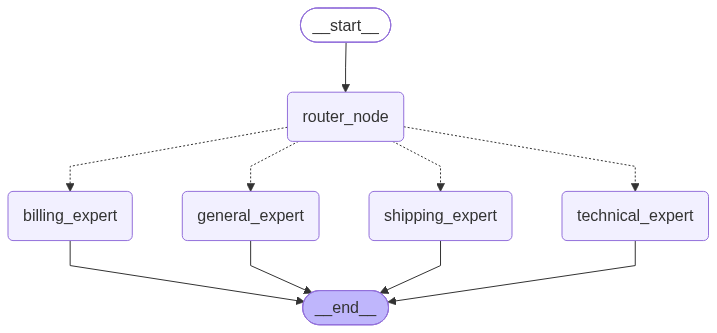

In [84]:
app

##3-5. 실행

In [85]:
app.invoke({"query": "지난달 요금이 두 번 빠져나갔어요. 확인해주세요."})


--- [Router] 문의 분석 중: '지난달 요금이 두 번 빠져나갔어요. 확인해주세요.' ---
   -> 분류 결과: BILLING 부서로 연결합니다.
--- [Billing Expert] 결제 전문가가 답변 작성 중 ---


{'query': '지난달 요금이 두 번 빠져나갔어요. 확인해주세요.',
 'category': 'billing',
 'response': '안녕하세요 고객님,  \n먼저 불편을 드려 죄송합니다. 말씀해주신 지난달 요금이 두 번 결제된 건에 대해 신속히 확인해드리겠습니다.  \n고객님의 계정 정보 확인을 위해 회원님의 성함 또는 가입하신 이메일 주소를 알려주시면 감사하겠습니다.  \n확인 후 빠른 시일 내에 환불 절차 및 처리 상황을 안내드리겠습니다.  \n감사합니다.'}

In [86]:
app.invoke({"query": "API 연결할 때 404 에러가 자꾸 떠요."})


--- [Router] 문의 분석 중: 'API 연결할 때 404 에러가 자꾸 떠요.' ---
   -> 분류 결과: TECHNICAL 부서로 연결합니다.
--- [Tech Expert] 기술 지원 엔지니어가 분석 중 ---


{'query': 'API 연결할 때 404 에러가 자꾸 떠요.',
 'category': 'technical',
 'response': 'API 연결 시 404 에러가 발생하는 경우, 이는 클라이언트가 요청한 리소스를 서버에서 찾지 못했다는 의미입니다. 404 에러를 해결하기 위한 점검 사항과 해결책을 아래에 정리했습니다.\n\n1. **URL 확인**\n   - 요청하는 API 엔드포인트(URL)가 정확한지 확인하세요.\n   - 오타, 경로 누락, 잘못된 버전 번호 등이 없는지 점검합니다.\n   - 예: `https://api.example.com/v1/users` vs `https://api.example.com/v2/users`\n\n2. **HTTP 메서드 확인**\n   - 요청 시 사용하는 HTTP 메서드(GET, POST, PUT, DELETE 등)가 API 문서와 일치하는지 확인하세요.\n   - 일부 API는 특정 경로에서 특정 메서드만 허용합니다.\n\n3. **API 문서 및 업데이트 확인**\n   - API가 업데이트되어 엔드포인트가 변경되었거나 삭제되었는지 공식 문서를 점검하세요.\n   - deprecated된 엔드포인트를 호출하는 경우도 404가 발생할 수 있습니다.\n\n4. **경로 변수 및 쿼리 파라미터 확인**\n   - 경로 변수(path parameters)가 올바르게 전달되었는지 확인하세요.\n   - 예: `/users/{userId}` 에서 `userId` 값이 올바른지 체크합니다.\n   - 쿼리 파라미터가 필요한 경우 빠뜨리지 않았는지도 확인합니다.\n\n5. **서버 설정 확인**\n   - 서버 측에서 해당 경로가 라우트되어 있는지, 올바르게 설정되어 있는지 확인합니다.\n   - 웹 서버나 API 게이트웨이 설정 오류로 경로가 매핑되지 않을 수 있습니다.\n\n6. **캐시 문제 확인**\n   - 클라이언트나 중간 프록시 캐시가 오래된 정보를 가지고 있을 수 있으니, 캐시를 지우거나 무시하고 요청해봅

In [87]:
app.invoke({"query": "주문한 노트북 언제 도착하나요?"})


--- [Router] 문의 분석 중: '주문한 노트북 언제 도착하나요?' ---
   -> 분류 결과: SHIPPING 부서로 연결합니다.
--- [Shipping Expert] 물류 담당자가 배송 조회 중 ---


{'query': '주문한 노트북 언제 도착하나요?',
 'category': 'shipping',
 'response': '안녕하세요, 고객님. 주문하신 노트북 배송 현황을 확인해 보겠습니다. 주문하신 날짜와 주문 번호를 알려주시면 보다 정확한 배송 일정을 안내해드릴 수 있습니다. 감사합니다.'}

#4 . Evaluator-Optimizer

##4-1. Model 정의

In [88]:
model = init_chat_model("gpt-5-nano", temperature=0.7)

##4-2. State 정의

In [89]:
class AdState(TypedDict):
    product_name: str       # 상품명
    ad_copy: str            # 생성된 홍보 문구
    feedback: str           # 피드백
    evaluate_status: str      # 검토 결과  "pass" or "fail"
    iteration_count: int


In [90]:
from pydantic import BaseModel, Field

class EvaluationResult(BaseModel):
    status: Literal["pass", "fail"] = Field(description = "평가 기준이 충족했는지를 정의")
    feedback: str = Field(description = "평가 기준에 충족하지 못한 경우, 수정해야 할 지시사항을 작성")


In [91]:
evaluator_llm = model.with_structured_output(EvaluationResult)

##4-3. Node 정의

In [92]:
# [Generator] 신입 카피라이터
def copywriter_node(state: AdState):
    product = state["product_name"]
    feedback = state.get('feedback')
    count = state.get('iteration_count', 0)
    print(f"\n--- [Copywriter] 광고 문구 작성 중 (시도: {count + 1}) ---")

    if not feedback:
        # 첫 시도는 좀 건조하게 작성하도록 유도 (Fail을 유발하기 위해)
        prompt = f"'{product}'의 기능 위주로 인스타그램 홍보 문구를 건조하게 작성해줘. 홍보 문구만 답변하고 반드시 20자 이하로 작성하시오."
    else:
        # 피드백 반영
        prompt = f"""
        '{product}' 인스타그램 홍보 문구를 다시 작성해.

        <반드시 지켜야 할 수정 사항>
        {feedback}
        </반드시 지켜야 할 수정 사항>

        <작성 시 반드시 지켜야할 사항>
        홍보 문구만 답변하고 절대 50자 이하로 작성하시오.
        </작성 시 반드시 지켜야할 사항>
        """

    msg = model.invoke(prompt)

    return {"ad_copy" : msg.content, "iteration_count" : count+1}

In [93]:
# [Evaluator] 감성적인 마케팅 팀장
def manager_node(state: AdState):
    ad_copy = state["ad_copy"]
    print(f"\n--- [Manager] 문구 검수 중 ---")

    print(f"   ㄴ 신입이 쓴 글: {ad_copy}")

    prompt = f"""
    당신은 깐깐한 마케팅 팀장입니다. 신입 사원이 쓴 다음 광고 문구를 평가하세요:

    "{ad_copy}"

    <평가 기준>
    1. (정량) 해시태그(#)가 3개 이상 있어야 합니다.
    2. (정량) '할인' 또는 '특가'라는 단어가 포함되어야 합니다.
    3. (정성 - 중요!) **문구가 너무 설명문 같거나 딱딱하면 안 됩니다. 소비자의 감성을 자극하는 '활기차고 매력적인 톤'이어야 합니다.**
    </평가 기준>

    위 3가지 기준 중 하나라도 부족하면 fail을 주세요.
    특히 3번(톤앤매너)이 부족하다면 "좀 더 감성적으로 쓰세요" 같이 100자 이내로 조언하세요.
    """
    evaluate_result = evaluator_llm.invoke(prompt)
    print(f"\n  *** 평가 결과 : {evaluate_result.status},  수정 지시 사항 : {evaluate_result.feedback}")
    return {"evaluate_status" : evaluate_result.status, "feedback" : evaluate_result.feedback}


##4-4. 그래프 생성

In [94]:
# 4. 루프 로직
def route_submission(state: AdState):
    status = state["evaluate_status"]
    count = state["iteration_count"]
    if status == "pass" :
        return END
    if count >= 3 :
        return END

    return "copywriter_node"


In [95]:
# 5. 그래프 생성
workflow = StateGraph(AdState)
workflow.add_node("copywriter_node", copywriter_node)
workflow.add_node("manager_node", manager_node)

workflow.add_edge(START, "copywriter_node")
workflow.add_edge("copywriter_node", "manager_node")
workflow.add_conditional_edges(
    "manager_node",
    route_submission,
    ["copywriter_node", END]
)


In [96]:
app = workflow.compile()

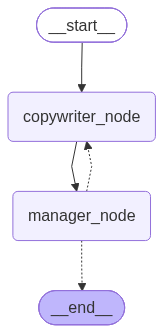

In [107]:
app

##4-5. 실행

In [108]:
inputs = {"product_name": "자율주행 자동차"}
result = app.invoke(inputs)


--- [Copywriter] 광고 문구 작성 중 (시도: 1) ---

--- [Manager] 문구 검수 중 ---
   ㄴ 신입이 쓴 글: 안전한 자율주행, 스마트한 이동


OpenAIPermissionDeniedError: Error code: 403 - {'error': {'message': 'Project `proj_gzhsh5AlJZLkdGZJdGouspxP` does not have access to model `gpt-5-nano`', 'type': 'invalid_request_error', 'param': None, 'code': 'model_not_found'}}

In [ ]:
result

#5 . Orchestrator-Worker

##5-1. Model 정의

In [ ]:
model = init_chat_model("gpt-5-nano")

##5-2. State 정의

In [ ]:
from typing import List

# 1. 데이터 모델 정의 (Plan & Section)
# 팀장(Orchestrator)이 짤 계획표의 양식
class Section(BaseModel):
    name : str = Field(description="목차의 제목")
    description : str = Field(description="이 목차에서 다뤄야 할 핵심 내용")


In [ ]:
import operator
from typing import Annotated

# 2. State 정의 (Reducer 필수!)
class ReportState(TypedDict):
    topic : str
    sections : List[Section]
    completed_sections : Annotated[List[str], operator.add]
    final_report : str


In [ ]:
# Worker에게 전달할 별도의 State (작업 지시서)
class WorkerState(TypedDict):
    section: Section

In [ ]:
class Plan(BaseModel):
    sections: List[Section] = Field(description="보고서 작성을 위한 목차 리스트")

In [ ]:
planner_llm = model.with_structured_output(Plan)

##5-3. Node 정의

In [ ]:
# [Orchestrator] 팀장 노드: 계획 수립
def orchestrator_node(state: ReportState):
    topic = state["topic"]
    print(f"\n--- [Orchestrator] '{topic}' 보고서 계획 수립 중 ---")

    # 보고서 목차를 생성 (최대 3개로 제한하여 속도 조절)
    plan = planner_llm.invoke(f"'{topic}'에 대한 보고서 목차를 짜줘. 5개 섹션 이내로 구성해.")

    print(f"생성된 계획: {[s.name for s in plan.sections]}")
    return {"sections": plan.sections}

In [ ]:
# [Worker] 팀원 노드: 섹션 집필
# 이 노드는 여러 개가 복제되어 동시에 실행
def worker_node(state: WorkerState):
    section = state["section"]
    print(f"   --- [Worker] 집필 중: {section.name} ---")

    prompt = f"""
    다음 섹션에 대한 내용을 짧게 작성해줘.
    제목: {section.name}
    내용 가이드: {section.description}
    """
    msg = model.invoke(prompt)
    content = f"## {section.name}\n{msg.content}\n"

    return {"completed_sections": [content]}

In [ ]:
# [Synthesizer] 편집자 노드: 취합
def synthesizer_node(state: ReportState):
    print("\n--- [Synthesizer] 모든 원고 취합 및 최종 편집 ---")

    # 리스트에 모인 조각글들을 하나로 합침
    completed = state.get("completed_sections", [])
    print(f"\n--- [Synthesizer] completed : {len(completed)}")
    final_report = "\n".join(completed)

    print(f"\n--- [Synthesizer] final ---\n {final_report}")

    return {"final_report": final_report}

##5-4. 그래프 생성

[Send API](https://reference.langchain.com/python/langgraph/types/?h=send#langgraph.types.Send)

In [ ]:
from langgraph.types import Send

# 5. 동적 라우팅 로직 (Map: 1 -> N)
# 일반적인 edge가 아니라, 리스트 개수만큼 노드를 생성해서 뿌려주는 역할
def assign_workers(state: ReportState):
    sections = state["sections"]

    return [Send("worker_node", {"section": s}) for s in sections]

In [ ]:
# 6. 그래프 조립
workflow = StateGraph(ReportState)

workflow.add_node("orchestrator_node", orchestrator_node)
workflow.add_node("worker_node", worker_node)
workflow.add_node("synthesizer_node", synthesizer_node)

# 6-1. 시작 -> 팀장
workflow.add_edge(START, "orchestrator_node")

# 6-2. 팀장 -> (Map) -> 팀원들 (Conditional Edge)
workflow.add_conditional_edges(
    "orchestrator_node",
    assign_workers,
    ["worker_node"]
)

# 6-3. 팀원들 -> (Reduce) -> 편집자
workflow.add_edge("worker_node", "synthesizer_node")

# 6-4. 편집자 -> 종료
workflow.add_edge("synthesizer_node", END)

In [ ]:
app = workflow.compile()

In [ ]:
app

##5-5. 실행

In [ ]:
inputs = {"topic": "생성형 AI의 미래"}
result = app.invoke(inputs)

In [ ]:
result["final_report"]

### develop (화학적 결합)

In [ ]:
# [Synthesizer] 편집자 노드: 단순 취합이 아니라 '화학적 결합'을 수행
def synthesizer_node(state: ReportState):
    topic = state["topic"]
    completed_docs = state["completed_sections"]

    print(f"\n--- [Synthesizer] 원고 {len(completed_docs)}건 도착. 최종 편집 시작 ---")

    # 1. 일단 텍스트 덩어리로 병합
    raw_content = "\n".join(completed_docs)


    # 2. LLM에게 '전문 편집자' 역할 부여
    prompt = f"""
    당신은 전문 리포트 편집자입니다.
    다음은 '{topic}'에 대해 여러 작가가 나누어 쓴 원고들입니다.

    이 초안들을 바탕으로 **하나의 자연스럽고 전문적인 보고서**로 다시 작성해주세요.

    [지시사항]
    1. 각 섹션의 연결이 매끄러워야 합니다.
    2. 전체를 아우르는 '서론'과 '결론'을 추가해주세요.
    3. 마크다운(Markdown) 형식을 사용하여 가독성을 높여주세요.

    [원고 내용]
    {raw_content}
    """

    # 최종 생성을 위한 LLM 호출
    msg = model.invoke(prompt)
    return {"final_report": msg.content}



In [ ]:
# 6. 그래프 조립
workflow = StateGraph(ReportState)

workflow.add_node("orchestrator_node", orchestrator_node)
workflow.add_node("worker_node", worker_node)
workflow.add_node("synthesizer_node", synthesizer_node)

# 1. 시작 -> 팀장
workflow.add_edge(START, "orchestrator_node")

# 2. 팀장 -> (Map) -> 팀원들 (Conditional Edge)
workflow.add_conditional_edges(
    "orchestrator_node",
    assign_workers,
    ["worker_node"] # 이 부분은 생략 가능하지만 명시적으로 적어줌
)

# 3. 팀원들 -> (Reduce) -> 편집자
workflow.add_edge("worker_node", "synthesizer_node")

# 4. 편집자 -> 종료
workflow.add_edge("synthesizer_node", END)

In [ ]:
app = workflow.compile()

In [ ]:
app

In [ ]:
inputs = {"topic": "생성형 AI의 미래"}
result = app.invoke(inputs)

In [ ]:
result["final_report"]

In [ ]:
result